<a href="https://colab.research.google.com/github/lovely-1512/DOCGPT_AI_PROJECT/blob/main/DOCGPT_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Install dependencies**

In [3]:
!pip install -q pypdf python-pptx python-docx sentence-transformers faiss-cpu \
    rank-bm25 transformers accelerate langchain-text-splitters streamlit openpyxl groq

**Groq setup (use Colab Secrets, never hardcode)**

In [4]:
import os
from google.colab import userdata
from groq import Groq

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
GROQ_MODEL = "openai/gpt-oss-120b"
groq_client = Groq(api_key=os.environ["GROQ_API_KEY"])
print("Groq ready:", GROQ_MODEL)

Groq ready: openai/gpt-oss-120b


**Imports & GPU check**

In [5]:
import os, re, shutil, time, json, sqlite3, hashlib
from collections import Counter
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, faiss
from pypdf import PdfReader
from pptx import Presentation
from docx import Document
from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sklearn.manifold import TSNE

print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))

for f in ["raw_data", "processed_data", "embeddings", "vector_db", "results", "logs"]:
    os.makedirs(f, exist_ok=True)
print("Folders ready.")

PyTorch: 2.11.0+cu130 | GPU: True
GPU: Tesla T4
Folders ready.


**Upload documents**

In [6]:
from google.colab import files
uploaded = files.upload()
for name in uploaded: shutil.move(name, f"raw_data/{name}")
print("Saved:", os.listdir("raw_data"))

Saving AI and Generative AI.pptx to AI and Generative AI.pptx
Saved: ['AI and Generative AI.pptx']


**Project Configuration & Quality Gates**


In [8]:
PROJECT_NAME, PROJECT_VERSION = "DocGPT AI", "1.0"
SUPPORTED_EXTENSIONS = {"pdf","pptx","docx","txt","csv","xlsx"}
MAX_FILE_SIZE_MB, CHUNK_SIZE, CHUNK_OVERLAP = 200, 700, 120
RRF_K, CANDIDATE_K, FINAL_K = 60, 12, 5
print(f"{PROJECT_NAME} v{PROJECT_VERSION} | chunk={CHUNK_SIZE}/{CHUNK_OVERLAP}")

DocGPT AI v1.0 | chunk=700/120


**Text cleaning + validation**

In [10]:
def clean_text(t):
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", t)
    return t.strip()

def create_document_id(p):
    with open(p, "rb") as f: return hashlib.sha256(f.read()).hexdigest()[:16]

def validate_file(p):
    ext = p.lower().rsplit(".", 1)[-1]
    mb = os.path.getsize(p) / (1024*1024)
    ok = ext in SUPPORTED_EXTENSIONS and mb <= MAX_FILE_SIZE_MB
    return {"valid": ok, "extension": ext, "size_mb": round(mb, 2),
            "reason": "ok" if ok else "unsupported or too large"}

preview = [{"file": f, **validate_file(f"raw_data/{f}")} for f in sorted(os.listdir("raw_data"))]
display(pd.DataFrame(preview)) if preview else print("No files.")

,file,valid,extension,size_mb,reason
0,AI and Generative AI.pptx,True,pptx,2.17,ok


**Document loaders (all formats)**

In [11]:
def read_pdf(p):
    did, recs = create_document_id(p), []
    for i, page in enumerate(PdfReader(p).pages, 1):
        t = clean_text(page.extract_text() or "")
        if t: recs.append({"document_id":did,"source":os.path.basename(p),"file_type":"PDF",
                           "location_type":"page","location":f"Page {i}","page":i,"slide":None,"text":t})
    return recs

def read_pptx(p):
    did, recs = create_document_id(p), []
    for i, s in enumerate(Presentation(p).slides, 1):
        parts = [sh.text.strip() for sh in s.shapes if hasattr(sh,"text") and sh.text.strip()]
        t = clean_text("\n".join(parts))
        if t: recs.append({"document_id":did,"source":os.path.basename(p),"file_type":"PPTX",
                           "location_type":"slide","location":f"Slide {i}","page":None,"slide":i,"text":t})
    return recs

def read_docx(p):
    did, recs, n = create_document_id(p), [], 0
    for para in Document(p).paragraphs:
        t = clean_text(para.text)
        if t:
            n += 1
            recs.append({"document_id":did,"source":os.path.basename(p),"file_type":"DOCX",
                         "location_type":"paragraph","location":f"Paragraph {n}",
                         "page":None,"slide":None,"text":t})
    return recs

def read_txt(p):
    did = create_document_id(p)
    for enc in ["utf-8","utf-8-sig","cp1252","latin-1"]:
        try:
            t = clean_text(open(p, encoding=enc).read()); break
        except UnicodeDecodeError: continue
    else: return []
    return [{"document_id":did,"source":os.path.basename(p),"file_type":"TXT",
             "location_type":"document","location":"Full document","page":None,"slide":None,"text":t}] if t else []

def read_tabular(p):
    did = create_document_id(p)
    ext = p.lower().rsplit(".", 1)[-1]
    try: df = pd.read_csv(p) if ext == "csv" else pd.read_excel(p)
    except UnicodeDecodeError: df = pd.read_csv(p, encoding="latin-1")
    df = df.dropna(axis=0, how="all").dropna(axis=1, how="all")
    out = []
    for rn, row in df.fillna("").iterrows():
        vals = [f"{c}: {row[c]}" for c in df.columns if str(row[c]).strip()]
        t = clean_text(" | ".join(vals))
        if t: out.append({"document_id":did,"source":os.path.basename(p),"file_type":ext.upper(),
                          "location_type":"row","location":f"Row {rn+2}","page":None,"slide":None,"text":t})
    return out

def read_xlsx(p):
    did, out = create_document_id(p), []
    for sheet in pd.ExcelFile(p).sheet_names:
        df = pd.read_excel(p, sheet_name=sheet).dropna(axis=0, how="all").dropna(axis=1, how="all")
        for rn, row in df.fillna("").iterrows():
            vals = [f"{c}: {row[c]}" for c in df.columns if str(row[c]).strip()]
            t = clean_text(" | ".join(vals))
            if t: out.append({"document_id":did,"source":os.path.basename(p),"file_type":"XLSX",
                              "location_type":"sheet_row","location":f"Sheet: {sheet} • Row: {rn+2}",
                              "page":None,"slide":None,"text":t})
    return out

def load_document(p):
    ext = p.lower().rsplit(".", 1)[-1]
    return {"pdf":read_pdf,"pptx":read_pptx,"docx":read_docx,"txt":read_txt,
            "csv":read_tabular,"xlsx":read_xlsx}.get(ext, lambda _: [])(p)

document_units = []
for f in os.listdir("raw_data"):
    document_units.extend(load_document(f"raw_data/{f}"))
document_units = [u for u in document_units if u["text"]]
print(f"Extracted {len(document_units)} units from {len(set(u['source'] for u in document_units))} documents")

Extracted 20 units from 1 documents


**Chunking**

In [12]:
splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n","\n",". ","? ","! ","; "," ",""])
chunk_records, cid = [], 0
for u in document_units:
    for n, chunk in enumerate(splitter.split_text(u["text"]), 1):
        chunk_records.append({**{k: u[k] for k in
            ["document_id","source","file_type","location_type","location","page","slide"]},
            "chunk_id":cid, "chunk_number":n, "text":chunk,
            "indexed_at":datetime.now(timezone.utc).isoformat()})
        cid += 1
chunk_df = pd.DataFrame(chunk_records)
chunk_df.to_csv("processed_data/chunks.csv", index=False)
print(f"{len(chunk_df)} chunks from {chunk_df['source'].nunique()} docs")
display(chunk_df.head(3))

20 chunks from 1 docs


,document_id,source,file_type,location_type,location,page,slide,chunk_id,chunk_number,text,indexed_at
0,e3beb9a5838b641d,AI and Generative AI.pptx,PPTX,slide,Slide 1,None,1,0,1,AN Industrial training on ai and generative ai...,2026-10-17T19:50:48.980909+00:00
1,e3beb9a5838b641d,AI and Generative AI.pptx,PPTX,slide,Slide 2,None,2,1,1,certificate,2026-10-17T19:50:48.981039+00:00
2,e3beb9a5838b641d,AI and Generative AI.pptx,PPTX,slide,Slide 3,None,3,2,1,Hardware and software requirements Hardware : ...,2026-10-17T19:50:48.981121+00:00


**Quick EDA**

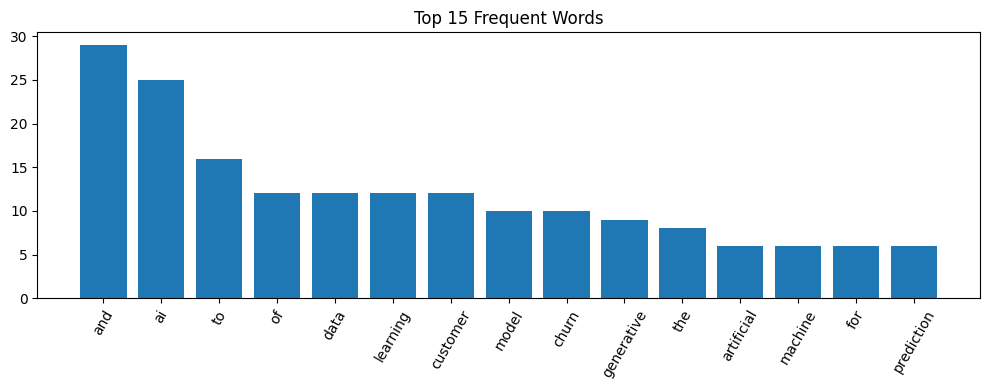

Docs: 1 | Chunks: 20


,count
file_type,
PPTX,20


,count
source,
AI and Generative AI.pptx,20


Locations indexed: 20


In [13]:
top = Counter(" ".join(chunk_df["text"]).lower().split()).most_common(15)
plt.figure(figsize=(10,4))
plt.bar([w for w,_ in top], [c for _,c in top]); plt.xticks(rotation=60)
plt.title("Top 15 Frequent Words"); plt.tight_layout(); plt.show()

print("=" * 60)
print(f"Docs: {chunk_df['source'].nunique()} | Chunks: {len(chunk_df)}")
display(chunk_df["file_type"].value_counts())
display(chunk_df["source"].value_counts())
print("Locations indexed:", chunk_df["location"].notna().sum())

**Embeddings + FAISS**

In [14]:
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL)
embeddings = embedding_model.encode(chunk_df["text"].tolist(), batch_size=32,
    show_progress_bar=True, normalize_embeddings=True).astype("float32")
np.save("embeddings/chunk_embeddings.npy", embeddings)
index = faiss.IndexFlatIP(embeddings.shape[1]); index.add(embeddings)
faiss.write_index(index, "vector_db/faiss_index.bin")
print(f"Shape: {embeddings.shape} | FAISS: {index.ntotal}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Shape: (20, 384) | FAISS: 20


**BM25**

In [15]:
def tokenize(t): return re.findall(r"\b\w+\b", t.lower())
tokenized_corpus = [tokenize(t) for t in chunk_df["text"]]
bm25 = BM25Okapi(tokenized_corpus)
print("BM25 indexed:", len(tokenized_corpus))

BM25 indexed: 20


**Hybrid retrieval + reranker**

In [16]:
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", max_length=512)

def hybrid_retrieve(query, candidate_k=CANDIDATE_K):
    if index is None or bm25 is None or chunk_df.empty:
        raise RuntimeError("Index/BM25/chunks not ready.")
    qe = embedding_model.encode([query], normalize_embeddings=True).astype("float32")
    _, sem = index.search(qe, min(candidate_k, len(chunk_df)))
    sem = sem[0].tolist()
    kw = np.argsort(bm25.get_scores(tokenize(query)))[::-1][:candidate_k].tolist()
    rrf = {}
    for rank, i in enumerate(sem, 1): rrf[i] = rrf.get(i,0) + 1/(RRF_K+rank)
    for rank, i in enumerate(kw, 1):  rrf[i] = rrf.get(i,0) + 1/(RRF_K+rank)
    ranked = sorted(rrf.items(), key=lambda x: x[1], reverse=True)
    out = []
    for i, s in ranked:
        r = chunk_df.iloc[i]
        out.append({"chunk_id":int(r["chunk_id"]),"document_id":r["document_id"],
            "source":r["source"],"file_type":r["file_type"],"location":r["location"],
            "page":r["page"],"slide":r["slide"],"chunk_number":int(r["chunk_number"]),
            "text":r["text"],"rrf_score":float(s)})
    return out

def rerank_results(query, candidates, top_k=FINAL_K):
    if not candidates: return []
    scores = reranker.predict([(query, c["text"]) for c in candidates])
    for c, s in zip(candidates, scores): c["reranker_score"] = float(s)
    return sorted(candidates, key=lambda x: x["reranker_score"], reverse=True)[:top_k]

# Smoke test
q = "What is Artificial Intelligence?"
for i, r in enumerate(rerank_results(q, hybrid_retrieve(q, 12), 3), 1):
    print(f"#{i} {r['source']} • {r['location']} • score={r['reranker_score']:.3f}")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

#1 AI and Generative AI.pptx • Slide 4 • score=7.250
#2 AI and Generative AI.pptx • Slide 9 • score=4.998
#3 AI and Generative AI.pptx • Slide 19 • score=3.967


**RAG generation (Groq)**

In [17]:
def build_context(results):
    blocks = []
    for i, r in enumerate(results, 1):
        blocks.append(f"[EVIDENCE {i}]\nSource: {r['source']}\nLocation: {r['location']}\nContent:\n{r['text']}\n")
    return "\n".join(blocks)

def ask_rag(question, candidate_k=12, final_k=5, max_new_tokens=300):
    evidence = rerank_results(question, hybrid_retrieve(question, candidate_k), final_k)
    if not evidence:
        return {"answer":"I could not find this information in the uploaded documents.",
                "citations":[], "confidence":0.0, "evidence":[]}
    system = """You are DocGPT AI, an evidence-first assistant. Answer using ONLY the evidence.
Rules: no outside knowledge, no invented facts. If unsupported, say:
"I could not find this information in the uploaded documents." Cite [Evidence N].
Never show reasoning or <think> tags. Return only the final answer."""
    user = f"Evidence:\n\n{build_context(evidence)}\n\nQuestion: {question}\n\nAnswer using only the evidence above."
    try:
        resp = groq_client.chat.completions.create(
            model=GROQ_MODEL,
            messages=[{"role":"system","content":system},{"role":"user","content":user}],
            temperature=0.7, max_tokens=max_new_tokens,
            reasoning_effort="low", reasoning_format="hidden")
        ans = resp.choices[0].message.content.strip()
        if "</think>" in ans: ans = ans.split("</think>")[-1].strip()
    except Exception as e:
        return {"answer":f"Groq API error: {e}","citations":[],"confidence":0.0,"evidence":[]}
    citations = [{"evidence_id":i,"source":r["source"],"location":r["location"],
                  "reranker_score":r.get("reranker_score",0)} for i, r in enumerate(evidence, 1)]
    return {"answer":ans, "citations":citations,
            "confidence":float(np.mean([r.get("reranker_score",0) for r in evidence])),
            "evidence":evidence}

res = ask_rag("What is Artificial Intelligence?")
print("ANSWER:\n", res["answer"], "\n")
for c in res["citations"]: print(f"[{c['evidence_id']}] {c['source']} • {c['location']}")
print("Confidence:", round(res["confidence"], 3))

ANSWER:
 Artificial Intelligence enables machines to perform human‑like tasks, serving as the foundation of smart automation. It can learn from data and improve its performance automatically, saving time, reducing human effort, and increasing efficiency【Evidence 1】 

[1] AI and Generative AI.pptx • Slide 4
[2] AI and Generative AI.pptx • Slide 9
[3] AI and Generative AI.pptx • Slide 19
[4] AI and Generative AI.pptx • Slide 6
[5] AI and Generative AI.pptx • Slide 8
Confidence: 3.758


**Backend module (rag_pipeline.py)**

In [18]:
%%writefile rag_pipeline.py
"""DocGPT AI — Evidence-first backend: load → chunk → embed → RRF → rerank → Groq LLM."""
import os, re, hashlib, time
import numpy as np, pandas as pd, faiss
from groq import Groq
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from pypdf import PdfReader
from pptx import Presentation
from docx import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RERANKER_MODEL  = "cross-encoder/ms-marco-MiniLM-L-6-v2"
GROQ_MODEL      = "openai/gpt-oss-120b"
GROQ_API_KEY    = os.environ.get("GROQ_API_KEY")
if not GROQ_API_KEY: raise RuntimeError("GROQ_API_KEY missing")
groq_client = Groq(api_key=GROQ_API_KEY)
RRF_K, DEFAULT_FINAL_K, DEFAULT_CANDIDATE_K, MAX_CONTEXT_CHARS = 60, 5, 12, 12000

print("Loading models...")
embedding_model = SentenceTransformer(EMBEDDING_MODEL)
reranker = CrossEncoder(RERANKER_MODEL, max_length=512)
print("Models loaded with Groq Cloud.")

# ---------- utils ----------
def create_document_id(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()[:16]

def clean_text(t):
    t = re.sub(r"\s+", " ", t)
    return re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", t).strip()

def clean_llm_output(t):
    if not t: return ""
    t = str(t).strip()
    if "<think>" in t:
        parts = t.split("</think>", 1)
        t = parts[1].strip() if len(parts) == 2 else t.split("<think>", 1)[0].strip()
    t = re.sub(r"<think>.*?</think>", "", t, flags=re.DOTALL | re.IGNORECASE)
    for p in [r"^\s*Thinking Process.*$", r"^\s*Constraint Checklist.*$",
              r"^\s*Analyze the Request.*$", r"^\s*Analyze the Evidence.*$",
              r"^\s*Confidence Score.*$", r"^\s*Return ONLY.*$"]:
        t = re.sub(p, "", t, flags=re.IGNORECASE | re.MULTILINE)
    return t.strip()

def tokenize_bm25(t): return re.findall(r"\b\w+\b", t.lower())

# ---------- loaders ----------
def read_pdf(p):
    did, recs = create_document_id(p), []
    for i, pg in enumerate(PdfReader(p).pages, 1):
        t = clean_text(pg.extract_text() or "")
        if t: recs.append(dict(document_id=did, source=os.path.basename(p), file_type="PDF",
            location_type="page", location=f"Page {i}", page=i, slide=None, text=t))
    return recs

def read_pptx(p):
    did, recs = create_document_id(p), []
    for i, s in enumerate(Presentation(p).slides, 1):
        t = clean_text("\n".join(sh.text.strip() for sh in s.shapes if hasattr(sh,"text") and sh.text.strip()))
        if t: recs.append(dict(document_id=did, source=os.path.basename(p), file_type="PPTX",
            location_type="slide", location=f"Slide {i}", page=None, slide=i, text=t))
    return recs

def read_docx(p):
    did, recs, n = create_document_id(p), [], 0
    for para in Document(p).paragraphs:
        t = clean_text(para.text)
        if t:
            n += 1
            recs.append(dict(document_id=did, source=os.path.basename(p), file_type="DOCX",
                location_type="paragraph", location=f"Paragraph {n}", page=None, slide=None, text=t))
    return recs

def read_txt(p):
    did = create_document_id(p); t = ""
    for enc in ["utf-8","utf-8-sig","cp1252","latin-1"]:
        try: t = open(p, encoding=enc).read(); break
        except UnicodeDecodeError: continue
    t = clean_text(t)
    return [dict(document_id=did, source=os.path.basename(p), file_type="TXT",
        location_type="document", location="Full document", page=None, slide=None, text=t)] if t else []

def read_tabular(p):
    did = create_document_id(p); ext = p.lower().rsplit(".",1)[-1]
    try: df = pd.read_csv(p) if ext=="csv" else pd.read_excel(p)
    except UnicodeDecodeError: df = pd.read_csv(p, encoding="latin-1")
    df = df.dropna(axis=0, how="all").dropna(axis=1, how="all")
    out = []
    for rn, row in df.fillna("").iterrows():
        t = clean_text(" | ".join(f"{c}: {row[c]}" for c in df.columns if str(row[c]).strip()))
        if t: out.append(dict(document_id=did, source=os.path.basename(p), file_type=ext.upper(),
            location_type="row", location=f"Row {rn+2}", page=None, slide=None, text=t))
    return out

def read_xlsx(p):
    did, out = create_document_id(p), []
    for sh in pd.ExcelFile(p).sheet_names:
        df = pd.read_excel(p, sheet_name=sh).dropna(axis=0, how="all").dropna(axis=1, how="all")
        for rn, row in df.fillna("").iterrows():
            t = clean_text(" | ".join(f"{c}: {row[c]}" for c in df.columns if str(row[c]).strip()))
            if t: out.append(dict(document_id=did, source=os.path.basename(p), file_type="XLSX",
                location_type="sheet_row", location=f"Sheet: {sh} • Row: {rn+2}",
                page=None, slide=None, text=t))
    return out

def load_document(p):
    ext = p.lower().rsplit(".", 1)[-1]
    return {"pdf":read_pdf,"pptx":read_pptx,"docx":read_docx,"txt":read_txt,
            "csv":read_tabular,"xlsx":read_xlsx}.get(ext, lambda _: [])(p)

# ---------- engine ----------
class DocGPTEngine:
    def __init__(self):
        self.chunk_df = pd.DataFrame(); self.index = None; self.bm25 = None
        self.document_units = []; self.embeddings = None
        self.ready = False; self.documents = []; self.total_chunks = 0

    def build_knowledge_base(self, file_paths):
        t0 = time.time(); units = []
        for p in file_paths: units.extend(load_document(p))
        if not units:
            self.ready = False
            return {"success":False, "message":"No readable text.", "documents":[], "chunks":0}
        self.document_units = units
        splitter = RecursiveCharacterTextSplitter(chunk_size=700, chunk_overlap=120,
            separators=["\n\n","\n",". ","? ","! ","; "," ",""])
        recs, cid = [], 0
        for u in units:
            for n, chunk in enumerate(splitter.split_text(u["text"]), 1):
                recs.append({**{k:u[k] for k in ["document_id","source","file_type",
                    "location_type","location","page","slide"]},
                    "chunk_id":cid, "chunk_number":n, "text":chunk,
                    "indexed_at":time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())})
                cid += 1
        self.chunk_df = pd.DataFrame(recs)
        if self.chunk_df.empty:
            self.ready = False
            return {"success":False, "message":"No usable chunks.", "documents":[], "chunks":0}
        texts = self.chunk_df["text"].tolist()
        self.embeddings = embedding_model.encode(texts, batch_size=32,
            show_progress_bar=False, normalize_embeddings=True).astype("float32")
        self.index = faiss.IndexFlatIP(self.embeddings.shape[1]); self.index.add(self.embeddings)
        self.bm25 = BM25Okapi([tokenize_bm25(t) for t in texts])
        self.documents = sorted(self.chunk_df["source"].unique().tolist())
        self.total_chunks = len(self.chunk_df); self.ready = True
        return {"success":True, "message":"Knowledge base created.",
                "documents":self.documents, "chunks":self.total_chunks,
                "document_units":len(self.document_units),
                "processing_time":round(time.time()-t0, 2)}

    def hybrid_retrieve(self, query, candidate_k=DEFAULT_CANDIDATE_K):
        if not self.ready: return []
        qe = embedding_model.encode([query], normalize_embeddings=True).astype("float32")
        _, sem = self.index.search(qe, min(candidate_k, len(self.chunk_df)))
        sem = sem[0].tolist()
        kw = np.argsort(self.bm25.get_scores(tokenize_bm25(query)))[::-1][:candidate_k].tolist()
        rrf = {}
        for rank, i in enumerate(sem, 1): rrf[i] = rrf.get(i,0) + 1/(RRF_K+rank)
        for rank, i in enumerate(kw, 1):  rrf[i] = rrf.get(i,0) + 1/(RRF_K+rank)
        out = []
        for i, s in sorted(rrf.items(), key=lambda x: x[1], reverse=True):
            r = self.chunk_df.iloc[i]
            out.append({"chunk_id":int(r["chunk_id"]),"document_id":r["document_id"],
                "source":r["source"],"file_type":r["file_type"],"location":r["location"],
                "page":r["page"],"slide":r["slide"],"chunk_number":int(r["chunk_number"]),
                "text":r["text"],"rrf_score":float(s)})
        return out

    def rerank(self, query, candidates, final_k=DEFAULT_FINAL_K):
        if not candidates: return []
        scores = reranker.predict([(query, c["text"]) for c in candidates])
        for c, s in zip(candidates, scores): c["reranker_score"] = float(s)
        return sorted(candidates, key=lambda x: x["reranker_score"], reverse=True)[:final_k]

    def calculate_retrieval_confidence(self, evidence):
        if not evidence:
            return {"score":0.0, "label":"Low", "type":"heuristic"}
        scores = np.array([e.get("reranker_score", e.get("score",0.0)) for e in evidence])
        top_sig = 1/(1+np.exp(-np.clip(scores[0], -10, 10)))
        ev_sig = min(len(evidence)/5.0, 1.0)
        mgn = scores[0]-scores[1] if len(scores) >= 2 else 0.0
        mgn_sig = 1/(1+np.exp(-np.clip(mgn, -10, 10)))
        c = float(np.clip(0.5*top_sig + 0.3*ev_sig + 0.2*mgn_sig, 0, 1))
        return {"score":c, "label":"High" if c >= 0.75 else "Medium" if c >= 0.5 else "Low",
                "type":"heuristic"}

    def build_evidence_context(self, evidence):
        blocks, cur = [], 0
        for i, e in enumerate(evidence, 1):
            b = f"[EVIDENCE {i}]\nSource: {e['source']}\nLocation: {e['location']}\nContent:\n{e['text']}\n"
            if cur + len(b) > MAX_CONTEXT_CHARS: break
            blocks.append(b); cur += len(b)
        return "\n".join(blocks)

    def ask_rag(self, question, conversation_history=None, candidate_k=DEFAULT_CANDIDATE_K,
                final_k=DEFAULT_FINAL_K, max_new_tokens=300):
        t0 = time.time()
        if not self.ready:
            return {"answer":"Upload files first.","citations":[],"evidence":[],
                    "confidence":{"score":0.0,"label":"Low","type":"heuristic"},"latency":0.0}
        evidence = self.rerank(question, self.hybrid_retrieve(question, candidate_k), final_k)
        if not evidence:
            return {"answer":"No evidence found.","citations":[],"evidence":[],
                    "confidence":{"score":0.0,"label":"Low","type":"heuristic"},
                    "latency":round(time.time()-t0, 3)}
        ctx = self.build_evidence_context(evidence)
        hist = ""
        if conversation_history:
            hist = "\n".join(f"{m.get('role','')}: {m.get('content','')}"
                             for m in conversation_history[-6:] if m.get("content"))
        system = ("You are DocGPT AI. Answer using ONLY the supplied evidence. "
                  "Do not use outside knowledge. If unsupported, say "
                  "'I could not find sufficient information in the uploaded documents.' "
                  "Answer naturally. Use bullets for multiple facts, **bold** for key terms. "
                  "Never show reasoning, thinking, or <think> tags. Do not create a sources section.")
        user = (f"DOCUMENT CONTEXT:\n\n{ctx}\n\nUSER QUESTION:\n{question}\n\n"
                f"CONVERSATION:\n{hist}\n\nAnswer using only the document context.")
        try:
            resp = groq_client.chat.completions.create(
                model=GROQ_MODEL,
                messages=[{"role":"system","content":system},{"role":"user","content":user}],
                temperature=0.7, max_tokens=max_new_tokens,
                reasoning_effort="low", reasoning_format="hidden")
            answer = clean_llm_output(resp.choices[0].message.content or "")
        except Exception as e:
            answer = f"Groq API Error: {e}"
        citations = [{"evidence_id":i,"source":r["source"],"location":r["location"],
                      "page":r["page"],"slide":r["slide"],
                      "score":r["reranker_score"]} for i, r in enumerate(evidence, 1)]
        return {"answer":answer, "citations":citations, "evidence":evidence,
                "confidence":self.calculate_retrieval_confidence(evidence),
                "latency":round(time.time()-t0, 3)}

    def generate_study_material(self, topic, study_type, max_new_tokens=700):
        if not self.ready:
            return {"success":False,"content":"Please upload and process documents first.",
                    "evidence":[],"confidence":{"score":0.0,"label":"Low","type":"heuristic"}}
        evidence = self.rerank(topic, self.hybrid_retrieve(topic, 15), 6)
        if not evidence:
            return {"success":False,"content":"Insufficient evidence for this topic.",
                    "evidence":[],"confidence":{"score":0.0,"label":"Low","type":"heuristic"}}
        ctx = self.build_evidence_context(evidence)
        if study_type == "Viva Questions":
            inst = ("Create exactly 10 technical viva questions with short answers.\n"
                    "Return ONLY final Q&A. Format:\n### Question N\n**Question:** ...\n"
                    "**Answer:** ...\n**Source:** [Evidence N]\n"
                    "Use ONLY the evidence. No outside facts. Start with ### Question 1.")
        elif study_type.startswith("Multiple Choice Questions"):
            m = re.search(r"\((\d+)\s*questions?\)", study_type, re.IGNORECASE)
            n = int(m.group(1)) if m else 5
            inst = (f"Create exactly {n} MCQs. Return ONLY quiz. Format:\n"
                    f"1. Question\nA) ...\nB) ...\nC) ...\nD) ...\nCorrect Answer: A\n"
                    f"Exactly {n} questions. Four options each. One correct. No extra sections.")
        elif study_type == "Flashcards":
            inst = ("Create exactly 5 flashcards. Format:\n### Flashcard N\n**Question:** ...\n"
                    "**Answer:** ...\n**Key Term:** **term**\n**Source:** [Evidence N]\n"
                    "Use ONLY the evidence.")
        else:
            inst = ("Create structured revision notes:\n### Topic Overview\n### Key Concepts\n"
                    "### Important Definitions\n### Important Facts\n### Quick Revision\n"
                    "Use ONLY the evidence.")
        system = ("You are DocGPT AI Study Assistant. Use ONLY supplied evidence. "
                  "Never invent facts/citations. Return ONLY final content. No reasoning, "
                  "no analysis, no chain-of-thought. Use ### headings and **bold** key terms.")
        user = (f"Topic: {topic}\nStudy Mode: {study_type}\nTask:\n{inst}\n\n"
                f"EVIDENCE:\n{ctx}\n\nGenerate final study material now.")
        try:
            resp = groq_client.chat.completions.create(
                model=GROQ_MODEL,
                messages=[{"role":"system","content":system},{"role":"user","content":user}],
                temperature=0.0, max_tokens=max_new_tokens,
                reasoning_effort="low", reasoning_format="hidden")
            content = clean_llm_output(resp.choices[0].message.content or "")
        except Exception as e:
            content = f"Groq API Error: {e}"
        return {"success":True, "content":content, "evidence":evidence,
                "confidence":self.calculate_retrieval_confidence(evidence)}

        def document_health(self):
         if self.chunk_df.empty: return pd.DataFrame()
         rows = []
         for src, g in self.chunk_df.groupby("source"):
            rows.append({"Document":src, "File Type":g["file_type"].iloc[0],
                "Chunks":len(g), "Locations":g["location"].nunique(),
                "Characters":int(g["text"].str.len().sum()), "Status":"Indexed"})
         return pd.DataFrame(rows)

    def compare_documents(self, document_a, document_b, question,
                          top_k=8, max_new_tokens=500):
        t0 = time.time()
        if not self.ready:
            return {"success":False, "answer":"Upload and process documents first.",
                    "evidence":[], "confidence":{"score":0.0,"label":"Low","type":"heuristic"},
                    "documents":{"A":document_a,"B":document_b}}
        a = self.chunk_df[self.chunk_df["source"] == document_a].copy()
        b = self.chunk_df[self.chunk_df["source"] == document_b].copy()
        if a.empty or b.empty:
            return {"success":False, "answer":"Insufficient content in one or both documents.",
                    "evidence":[], "confidence":{"score":0.0,"label":"Low","type":"heuristic"},
                    "documents":{"A":document_a,"B":document_b}}
        a["reranker_score"] = reranker.predict([(question, t) for t in a["text"]])
        b["reranker_score"] = reranker.predict([(question, t) for t in b["text"]])
        a = a.sort_values("reranker_score", ascending=False)
        b = b.sort_values("reranker_score", ascending=False)
        k = max(2, top_k // 2)
        combined = pd.concat([a.head(k), b.head(k)], ignore_index=True) \
                     .sort_values("reranker_score", ascending=False)
        results = [{"source":r["source"], "location":r["location"], "page":r["page"],
                    "slide":r["slide"], "text":r["text"],
                    "reranker_score":float(r["reranker_score"]),
                    "score":float(r["reranker_score"])}
                   for _, r in combined.iterrows()]
        blocks, cur, n = [], 0, 1
        for item in results:
            label = "DOCUMENT A" if item["source"] == document_a else "DOCUMENT B"
            blk = (f"[EVIDENCE {n}]\nDocument: {label}\nSource: {item['source']}\n"
                   f"Location: {item['location']}\nContent:\n{item['text']}\n")
            if cur + len(blk) > MAX_CONTEXT_CHARS: break
            blocks.append(blk); cur += len(blk); n += 1
        ctx = "\n".join(blocks)
        system = ("You are DocGPT AI Comparison Assistant. Compare two documents using "
                  "ONLY supplied evidence. No invented differences/similarities. "
                  "Cite [Evidence N]. Use ### headings, bullets, and a Markdown table when useful. "
                  "Structure: ### Comparison Summary / ### Key Differences / ### Similarities / "
                  "### What Changed? / ### Conclusion. Bold important terms.")
        user = (f"DOCUMENT A: {document_a}\nDOCUMENT B: {document_b}\n"
                f"QUESTION: {question}\n\nEVIDENCE:\n{ctx}\n\nCompare A and B using only evidence.")
        try:
            resp = groq_client.chat.completions.create(
                model=GROQ_MODEL,
                messages=[{"role":"system","content":system},{"role":"user","content":user}],
                temperature=0.7, max_tokens=max_new_tokens,
                reasoning_effort="low", reasoning_format="hidden")
            answer = clean_llm_output(resp.choices[0].message.content or "")
        except Exception as e:
            answer = f"Groq API Comparison Error: {e}"
        citations = [{"evidence_id":i, "source":r["source"], "location":r["location"],
                      "score":r["reranker_score"]} for i, r in enumerate(results, 1)]
        return {"success":True, "answer":answer, "evidence":results, "citations":citations,
                "confidence":self.calculate_retrieval_confidence(results),
                "documents":{"A":document_a,"B":document_b},
                "latency":round(time.time()-t0, 3)}


def create_engine():
    return DocGPTEngine()

Writing rag_pipeline.py


**Backend smoke test**

In [19]:
from rag_pipeline import create_engine
test_engine = create_engine()
print("Backend import: SUCCESS")
print("Engine creation: SUCCESS")
print("Study method available:", hasattr(test_engine, "generate_study_material"))

Loading models...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Models loaded with Groq Cloud.
Backend import: SUCCESS
Engine creation: SUCCESS
Study method available: True


**Index documents & test RAG**

In [20]:
test_files = [f"raw_data/{f}" for f in os.listdir("raw_data")
              if f.lower().endswith((".pdf",".pptx",".docx",".txt",".csv",".xlsx"))]
if not test_files:
    print("No documents in raw_data.")
else:
    print(test_engine.build_knowledge_base(test_files))

res = test_engine.ask_rag("What is Artificial Intelligence?")
print("\nANSWER:\n", res["answer"])
print("\nCITATIONS:")
for c in res["citations"]:
    print(f"[{c['evidence_id']}] {c['source']} • {c['location']}")
print("\nConfidence:", res["confidence"])
print("Latency:", res["latency"], "sec")

{'success': True, 'message': 'Knowledge base created.', 'documents': ['AI and Generative AI.pptx'], 'chunks': 20, 'document_units': 20, 'processing_time': 0.06}

ANSWER:
 **Artificial Intelligence (AI)** is the capability that enables machines to perform human‑like tasks. It serves as the foundation for smart automation, allowing systems to learn from data, automatically improve their performance, save time, reduce human effort, and increase efficiency. AI is applied across many sectors, including healthcare, banking, education, and industry.

CITATIONS:
[1] AI and Generative AI.pptx • Slide 4
[2] AI and Generative AI.pptx • Slide 9
[3] AI and Generative AI.pptx • Slide 19
[4] AI and Generative AI.pptx • Slide 6
[5] AI and Generative AI.pptx • Slide 8

Confidence: {'score': 0.9806060678433122, 'label': 'High', 'type': 'heuristic'}
Latency: 0.743 sec


In [21]:
# ---- All-in-one backend test (self-contained) ----
import os, importlib, sys
from google.colab import userdata

# 1. Make sure API key is set
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

# 2. Force reload rag_pipeline so latest code is used
if "rag_pipeline" in sys.modules:
    importlib.reload(sys.modules["rag_pipeline"])
import rag_pipeline

# 3. Create engine
test_engine = rag_pipeline.create_engine()
print("✅ Engine ready:", type(test_engine).__name__)

# 4. Load documents from raw_data
test_files = [f"raw_data/{f}" for f in os.listdir("raw_data")
              if f.lower().endswith((".pdf",".pptx",".docx",".txt",".csv",".xlsx"))]

if not test_files:
    print("❌ No documents in raw_data. Upload files first.")
else:
    print("📄 Files:", test_files)
    result = test_engine.build_knowledge_base(test_files)
    print("Index result:", result)

    # 5. Ask a test question
    res = test_engine.ask_rag("What is Artificial Intelligence?")
    print("\n" + "="*60)
    print("ANSWER:\n", res["answer"])
    print("="*60)
    print("\nCITATIONS:")
    for c in res["citations"]:
        print(f"  [{c['evidence_id']}] {c['source']} • {c['location']}")
    print(f"\nConfidence: {res['confidence']}")
    print(f"Latency:    {res['latency']} sec")

Loading models...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Models loaded with Groq Cloud.
✅ Engine ready: DocGPTEngine
📄 Files: ['raw_data/AI and Generative AI.pptx']
Index result: {'success': True, 'message': 'Knowledge base created.', 'documents': ['AI and Generative AI.pptx'], 'chunks': 20, 'document_units': 20, 'processing_time': 0.06}

ANSWER:
 - **Artificial Intelligence (AI)** enables machines to perform human‑like tasks.  
- It serves as the **foundation of smart automation**, allowing systems to **learn from data and automatically improve their performance**.  
- AI **saves time, reduces human effort, and increases efficiency**, and it is widely applied in sectors such as **healthcare, banking, education, and industry**.

CITATIONS:
  [1] AI and Generative AI.pptx • Slide 4
  [2] AI and Generative AI.pptx • Slide 9
  [3] AI and Generative AI.pptx • Slide 19
  [4] AI and Generative AI.pptx • Slide 6
  [5] AI and Generative AI.pptx • Slide 8

Confidence: {'score': 0.9806060678433122, 'label': 'High', 'type': 'heuristic'}
Latency:    0.5

**Business Intelligence (inventory, diff, feedback, evaluation, tests)**

In [22]:
# 17.1 Document inventory
def build_inventory(df):
    if df.empty: return pd.DataFrame()
    inv = (df.groupby(["source","document_id","file_type"], as_index=False)
             .agg(chunks=("chunk_id","count"),
                  characters=("text", lambda s: int(s.str.len().sum())),
                  locations=("location","nunique"))
             .sort_values("chunks", ascending=False))
    inv["status"] = "Indexed"
    return inv
display(build_inventory(chunk_df))

# 17.2 Semantic document diff (run when two versions exist)
def semantic_diff(doc_a, doc_b, threshold=0.82):
    a = chunk_df[chunk_df["source"]==doc_a][["chunk_id","text","location"]].reset_index(drop=True)
    b = chunk_df[chunk_df["source"]==doc_b][["chunk_id","text","location"]].reset_index(drop=True)
    if a.empty or b.empty: raise ValueError("Both documents must exist.")
    av = embedding_model.encode(a["text"].tolist(), normalize_embeddings=True).astype("float32")
    bv = embedding_model.encode(b["text"].tolist(), normalize_embeddings=True).astype("float32")
    sim = np.matmul(av, bv.T)
    used, rows = set(), []
    for i, row in a.iterrows():
        j = int(np.argmax(sim[i])); sc = float(sim[i, j])
        if j in used:
            rows.append({"status":"Removed","old_location":row["location"],"new_location":None,
                         "similarity":sc,"old_text":row["text"],"new_text":""}); continue
        used.add(j); br = b.iloc[j]
        if sc >= 0.97 and row["text"].strip() == br["text"].strip(): st = "Unchanged"
        elif sc >= threshold: st = "Changed"
        else: st = "Removed"
        rows.append({"status":st,"old_location":row["location"],"new_location":br["location"],
                     "similarity":round(sc,4),"old_text":row["text"],"new_text":br["text"]})
    for j, row in b.iterrows():
        if j not in used:
            rows.append({"status":"Added","old_location":None,"new_location":row["location"],
                         "similarity":None,"old_text":"","new_text":row["text"]})
    return pd.DataFrame(rows)
print("Run semantic_diff('old.pdf','new.pdf') when two versions are indexed.")

# 17.3 Feedback & audit log
FEEDBACK_DB = "logs/docgpt_feedback.db"
with sqlite3.connect(FEEDBACK_DB) as c:
    c.execute("""CREATE TABLE IF NOT EXISTS interactions (
        id INTEGER PRIMARY KEY AUTOINCREMENT, timestamp TEXT, question TEXT,
        confidence REAL, latency_seconds REAL, evidence_count INTEGER,
        feedback TEXT, top_source TEXT)""")

def log_interaction(result, question, feedback=None):
    with sqlite3.connect(FEEDBACK_DB) as c:
        c.execute("INSERT INTO interactions(timestamp,question,confidence,latency_seconds,"
                  "evidence_count,feedback,top_source) VALUES (?,?,?,?,?,?,?)",
                  (datetime.now(timezone.utc).isoformat(), question,
                   float(result.get("confidence", 0)), float(result.get("latency", 0)),
                   len(result.get("evidence", [])), feedback,
                   result.get("evidence", [{}])[0].get("source") if result.get("evidence") else None))

def interaction_summary():
    with sqlite3.connect(FEEDBACK_DB) as c:
        df = pd.read_sql_query("SELECT * FROM interactions", c)
    if df.empty: return pd.DataFrame([{"interactions":0}])
    return pd.DataFrame([{"interactions":len(df),
        "avg_confidence":round(df["confidence"].mean(),3),
        "avg_latency_seconds":round(df["latency_seconds"].mean(),3),
        "low_confidence_rate":round((df["confidence"]<0.5).mean(),3)}])
display(interaction_summary())

# 17.4 Retrieval evaluation with ground-truth
def evaluate_retrieval(test_cases, k=5):
    rows = []
    for case in test_cases:
        exp = set(case.get("expected_sources", []))
        res = rerank_results(case["question"],
                hybrid_retrieve(case["question"], candidate_k=max(k, CANDIDATE_K)), top_k=k)
        got = [r["source"] for r in res]
        hit = bool(exp.intersection(got)) if exp else None
        rows.append({"question":case["question"], "expected_sources":", ".join(sorted(exp)),
                     "retrieved_sources":", ".join(got), f"Recall@{k}":int(hit) if hit is not None else None})
    return pd.DataFrame(rows)
print("evaluate_retrieval([{'question':'...','expected_sources':['x.pdf']}]) ready.")

# 17.5 Reliability tests
def run_reliability_tests():
    c = {"chunks_exist": len(chunk_df) > 0,
         "chunk_ids_unique": chunk_df["chunk_id"].is_unique if not chunk_df.empty else False,
         "sources_present": chunk_df["source"].notna().all() if not chunk_df.empty else False,
         "faiss_count_matches": index.ntotal == len(chunk_df) if "index" in globals() and not chunk_df.empty else False,
         "bm25_count_matches": len(tokenized_corpus) == len(chunk_df) if "tokenized_corpus" in globals() else False,
         "retriever_callable": callable(hybrid_retrieve),
         "reranker_callable": callable(rerank_results),
         "rag_callable": callable(ask_rag)}
    rep = pd.DataFrame([{"check":k,"status":"PASS" if v else "FAIL"} for k, v in c.items()])
    display(rep)
    return bool(rep["status"].eq("PASS").all())
run_reliability_tests()

,source,document_id,file_type,chunks,characters,locations,status
0,AI and Generative AI.pptx,e3beb9a5838b641d,PPTX,20,4897,20,Indexed


Run semantic_diff('old.pdf','new.pdf') when two versions are indexed.


,interactions
0,0


evaluate_retrieval([{'question':'...','expected_sources':['x.pdf']}]) ready.


,check,status
0,chunks_exist,PASS
1,chunk_ids_unique,PASS
2,sources_present,PASS
3,faiss_count_matches,PASS
4,bm25_count_matches,PASS
5,retriever_callable,PASS
6,reranker_callable,PASS
7,rag_callable,PASS


True

**Streamlit frontend (app.py)**

In [26]:
%%writefile app.py
import os, sys, json, uuid, sqlite3, time, re
from datetime import datetime
import streamlit as st

st.set_page_config(page_title="DocGPT AI", page_icon="📚", layout="wide")
sys.path.append(os.path.dirname(__file__))
from rag_pipeline import create_engine
try: from groq import Groq
except Exception: Groq = None

CHAT_HISTORY_FILE, USER_DB = "chat_history.json", "docgpt_users.db"
GROQ_MODEL, WHISPER_MODEL = "openai/gpt-oss-120b", "whisper-large-v3-turbo"

def initialize_database():
    with sqlite3.connect(USER_DB) as c:
        c.execute("CREATE TABLE IF NOT EXISTS users (username TEXT PRIMARY KEY, created_at TEXT)")
        c.execute("CREATE TABLE IF NOT EXISTS analytics (id INTEGER PRIMARY KEY AUTOINCREMENT, "
                  "username TEXT, event TEXT, created_at TEXT)")
initialize_database()

def log_event(event):
    user = st.session_state.get("username", "guest")
    try:
        with sqlite3.connect(USER_DB) as c:
            c.execute("INSERT INTO analytics(username,event,created_at) VALUES (?,?,?)",
                      (user, event, datetime.now().isoformat()))
    except Exception: pass

def load_chat_history():
    if not os.path.exists(CHAT_HISTORY_FILE): return {}
    try:
        with open(CHAT_HISTORY_FILE, encoding="utf-8") as f:
            d = json.load(f)
        return d if isinstance(d, dict) else {}
    except Exception: return {}

def save_chat_history(chats):
    try:
        with open(CHAT_HISTORY_FILE, "w", encoding="utf-8") as f:
            json.dump(chats, f, indent=2, ensure_ascii=False)
    except Exception: pass

def new_chat():
    return {"id": str(uuid.uuid4()), "title":"New Conversation", "messages":[],
            "created_at": datetime.now().isoformat(), "updated_at": datetime.now().isoformat()}

def make_title(msgs):
    for m in msgs:
        if m.get("role") == "user":
            w = m.get("content","").strip().split()
            return (" ".join(w[:7]) + "...") if len(w) > 7 else " ".join(w) or "New Conversation"
    return "New Conversation"

def save_current_chat():
    cid, msgs = st.session_state.current_chat_id, st.session_state.messages
    if not msgs: return
    prev = st.session_state.chat_history.get(cid, {})
    st.session_state.chat_history[cid] = {
        "id":cid, "title":make_title(msgs), "messages":msgs,
        "created_at":prev.get("created_at", datetime.now().isoformat()),
        "updated_at":datetime.now().isoformat()}
    save_chat_history(st.session_state.chat_history)

def load_chat(cid):
    c = st.session_state.chat_history.get(cid)
    if c:
        st.session_state.current_chat_id = cid
        st.session_state.messages = c.get("messages", [])

def delete_chat(cid):
    st.session_state.chat_history.pop(cid, None)
    save_chat_history(st.session_state.chat_history)
    st.session_state.current_chat_id = new_chat()["id"]
    st.session_state.messages = []

# ---------- session state ----------
for k, v in [("engine", None), ("messages", []), ("processed_files", []),
             ("mode", "Chat"), ("chat_history", None), ("current_chat_id", None),
             ("edit_index", None), ("answer_style", "Natural"), ("answer_length", "Medium"),
             ("show_analytics", False), ("username", "Guest")]:
    if k not in st.session_state:
        st.session_state[k] = create_engine() if k == "engine" else \
            load_chat_history() if k == "chat_history" else \
            new_chat()["id"] if k == "current_chat_id" else v

st.markdown("""<style>
.main-title{font-size:2.45rem;font-weight:800;margin-bottom:.05rem}
.subtitle{color:#777;font-size:.96rem;margin-bottom:1rem}
.history-heading{font-size:.8rem;font-weight:800;color:#777;margin:.5rem 0 .4rem;
  text-transform:uppercase;letter-spacing:.05em}
</style>""", unsafe_allow_html=True)
st.markdown('<div class="main-title">📚 DocGPT AI</div>', unsafe_allow_html=True)
st.markdown('<div class="subtitle">Your intelligent document workspace</div>', unsafe_allow_html=True)

# ---------- render helpers ----------
def render_ai_answer(c):
    st.markdown(c or "No answer generated.", unsafe_allow_html=False)

def render_confidence(conf, label="Grounding confidence"):
    if not conf: return
    try: s = float(conf.get("score", 0))
    except (TypeError, ValueError): s = 0.0
    st.caption(f"◉ {label}: {conf.get('label','Unknown')} • {s:.2f}")

def render_citations(cits):
    if not cits: return
    with st.expander("📚 Sources & Evidence", expanded=False):
        for i, c in enumerate(cits, 1):
            st.markdown(f"**{c.get('evidence_id', i)} · {c.get('source','Unknown')}**")
            st.caption(f"Location: {c.get('location','N/A')}")
            if i < len(cits): st.divider()

def render_evidence(ev, title="📚 Supporting Evidence"):
    if not ev: return
    with st.expander(title, expanded=False):
        for i, e in enumerate(ev, 1):
            st.markdown(f"**Evidence {i} · {e.get('source','Unknown')}**")
            st.caption(f"Location: {e.get('location','N/A')}")
            if e.get("text"): st.markdown(f"> {e['text']}")
            if i < len(ev): st.divider()

def style_instr():
    return {"Natural":"Answer naturally.","Simple":"Use very simple language.",
            "Detailed":"Deep explanation with examples.","Technical":"Technical accurate terms.",
            "Exam Answer":"Exam-ready structure.","Interview Answer":"Concise professional."}.get(
            st.session_state.answer_style, "Answer naturally.")

def length_instr():
    return {"Short":"2-5 sentences.","Medium":"Balanced short paragraphs.",
            "Detailed":"Comprehensive but focused."}.get(st.session_state.answer_length, "Balanced.")

# ---------- sidebar ----------
with st.sidebar:
    st.header("📚 DocGPT AI")
    if st.button("＋ New Chat", type="primary", use_container_width=True):
        save_current_chat(); st.session_state.current_chat_id = new_chat()["id"]
        st.session_state.messages = []; st.rerun()
    st.markdown('<div class="history-heading">💬 Previous Chats</div>', unsafe_allow_html=True)
    chats = sorted(st.session_state.chat_history.values(),
                   key=lambda x: x.get("updated_at",""), reverse=True)
    if not chats: st.caption("No previous chats yet.")
    for ch in chats:
        cid, title = ch.get("id"), ch.get("title","New Conversation")[:32]
        active = cid == st.session_state.current_chat_id
        if st.button(("● " if active else "  ") + title, key=f"open_{cid}", use_container_width=True):
            save_current_chat(); load_chat(cid); st.rerun()
        if active and st.button("🗑️ Delete this chat", key=f"del_{cid}", use_container_width=True):
            delete_chat(cid); st.rerun()
    st.divider(); st.subheader("🚀 Workspace")
    mode = st.radio("Mode", ["Chat","Compare","Study","Quiz"],
                    index=["Chat","Compare","Study","Quiz"].index(st.session_state.mode))
    st.session_state.mode = mode
    st.divider()
    if mode == "Chat":
        st.subheader("🎯 Answer Settings")
        st.session_state.answer_style = st.selectbox("Answer style",
            ["Natural","Simple","Detailed","Technical","Exam Answer","Interview Answer"],
            index=["Natural","Simple","Detailed","Technical","Exam Answer","Interview Answer"]
                  .index(st.session_state.answer_style))
        st.session_state.answer_length = st.select_slider("Answer length",
            options=["Short","Medium","Detailed"], value=st.session_state.answer_length)
        st.divider()
    st.subheader("📂 Documents")
    files = st.file_uploader("Upload files", type=["pdf","pptx","docx","txt","csv","xlsx"],
                             accept_multiple_files=True)
    if st.button("⚡ Process Documents", type="primary", use_container_width=True,
                 disabled=not files):
        os.makedirs("raw_data", exist_ok=True); paths = []
        for f in files:
            p = os.path.join("raw_data", os.path.basename(f.name))
            with open(p, "wb") as o: o.write(f.getbuffer())
            paths.append(p)
        with st.spinner("Analyzing, chunking and indexing..."):
            try: r = st.session_state.engine.build_knowledge_base(paths)
            except Exception as e: r = {"success":False, "message":str(e)}
        if r.get("success"):
            st.session_state.processed_files = r.get("documents", [])
            log_event("process_documents"); st.success(f"Indexed {r.get('chunks',0)} chunks.")
        else: st.error(r.get("message","Unable to process."))
    eng = st.session_state.engine
    if eng.ready:
        st.caption(f"🟢 {len(eng.documents)} docs • {eng.total_chunks} chunks")
        with st.expander("📄 Processed Documents"):
            for d in eng.documents: st.write(f"• {d}")
    else: st.info("Upload documents to begin.")
    st.divider()
    if mode == "Chat":
        st.subheader("🎙️ Voice Input")
        audio = st.audio_input("Record your question")
        if audio is not None and Groq:
            try:
                key = os.environ.get("GROQ_API_KEY")
                if key:
                    vc = Groq(api_key=key)
                    tr = vc.audio.transcriptions.create(
                        file=(audio.name, audio.getvalue()), model=WHISPER_MODEL)
                    st.session_state.voice_text = tr.text
                    st.success("Voice converted to text.")
            except Exception as e: st.error(f"Voice error: {e}")
        if st.session_state.get("voice_text"):
            st.text_area("Transcribed", value=st.session_state.voice_text, height=80, disabled=True)
            if st.button("💬 Ask this question", use_container_width=True):
                st.session_state.voice_prompt = st.session_state.voice_text
                st.session_state.voice_text = ""; st.rerun()
        st.divider()
    st.subheader("⚙️ Controls")
    if st.button("🧹 Clear Current Chat", use_container_width=True):
        st.session_state.messages = []
        st.session_state.chat_history.pop(st.session_state.current_chat_id, None)
        save_chat_history(st.session_state.chat_history); st.rerun()
    if st.button("🔄 Refresh", use_container_width=True):
        save_current_chat(); st.rerun()
    if st.session_state.messages:
        st.subheader("⬇️ Export")
        transcript = "\n".join(
            f"{'USER' if m.get('role')=='user' else 'DOCGPT AI'}:\n{m.get('content','')}\n"
            for m in st.session_state.messages)
        st.download_button("📄 Download TXT", transcript, "DocGPT_Conversation.txt",
                           mime="text/plain", use_container_width=True)
        st.download_button("📝 Download Markdown", transcript, "DocGPT_Conversation.md",
                           mime="text/markdown", use_container_width=True)
    st.divider()
    if st.button("📊 Usage Analytics", use_container_width=True):
        st.session_state.show_analytics = not st.session_state.show_analytics; st.rerun()
    st.caption(f"👤 {st.session_state.username}")

voice_prompt = st.session_state.pop("voice_prompt", None)

# ---------- CHAT ----------
if mode == "Chat":
    st.subheader("💬 Chat with your Documents")
    st.caption("Ask naturally and get grounded answers from your uploaded documents.")
    for i, m in enumerate(st.session_state.messages):
        role, content = m.get("role","assistant"), m.get("content","")
        with st.chat_message(role):
            if role == "user":
                st.markdown(content)
                c1, c2 = st.columns(2)
                with c1:
                    if st.button("✏️ Edit", key=f"edit_{i}"):
                        st.session_state.edit_index = i; st.rerun()
                with c2:
                    if st.button("🗑️ Delete", key=f"del_msg_{i}"):
                        del st.session_state.messages[i]
                        if i < len(st.session_state.messages) and \
                           st.session_state.messages[i].get("role") == "assistant":
                            del st.session_state.messages[i]
                        save_current_chat(); st.rerun()
            else:
                render_ai_answer(content)
                render_citations(m.get("citations", []))
                render_confidence(m.get("confidence", {}))
                c1, c2 = st.columns(2)
                with c1:
                    if st.button("🔄 Regenerate", key=f"regen_{i}") and i > 0:
                        prev = st.session_state.messages[i-1]
                        if prev.get("role") == "user":
                            q = prev["content"]; del st.session_state.messages[i]
                            with st.spinner("Regenerating..."):
                                try: r = eng.ask_rag(q, conversation_history=st.session_state.messages)
                                except Exception: r = {"answer":"Failed.","citations":[],"confidence":{}}
                            st.session_state.messages.insert(i, {
                                "role":"assistant","content":r.get("answer",""),
                                "citations":r.get("citations",[]),
                                "confidence":r.get("confidence",{}),
                                "latency":r.get("latency",0)})
                            save_current_chat(); st.rerun()
                with c2:
                    if st.button("📋 Copy-ready", key=f"copy_{i}"):
                        st.code(content, language=None)

    if st.session_state.edit_index is not None:
        idx = st.session_state.edit_index
        if idx < len(st.session_state.messages):
            old = st.session_state.messages[idx]
            st.divider(); st.markdown("### ✏️ Edit Message")
            new = st.text_area("Your message", value=old.get("content",""), height=120,
                               key="edited_message")
            c1, c2 = st.columns(2)
            with c1: save = st.button("✅ Save & Regenerate", type="primary", use_container_width=True)
            with c2: cancel = st.button("❌ Cancel", use_container_width=True)
            if cancel:
                st.session_state.edit_index = None; st.rerun()
            if save and new.strip():
                st.session_state.messages[idx]["content"] = new.strip()
                st.session_state.messages = st.session_state.messages[:idx+1]
                with st.spinner("Generating..."):
                    try: r = eng.ask_rag(new.strip(), conversation_history=st.session_state.messages)
                    except Exception: r = {"answer":"Failed.","citations":[],"confidence":{}}
                st.session_state.messages.append({"role":"assistant",
                    "content":r.get("answer",""), "citations":r.get("citations",[]),
                    "confidence":r.get("confidence",{}), "latency":r.get("latency",0)})
                st.session_state.edit_index = None; save_current_chat(); st.rerun()

    if st.session_state.messages and st.session_state.messages[-1].get("role") == "assistant":
        st.markdown("**💡 You may also ask**")
        cols = st.columns(2)
        for i, s in enumerate(["Explain this in simple words","Give me the key points",
                               "What are the important concepts?","Give me an example"]):
            with cols[i % 2]:
                if st.button(s, key=f"sug_{i}"):
                    st.session_state.suggested_prompt = s; st.rerun()

    prompt = st.chat_input("Ask anything about your documents...")
    if voice_prompt: prompt = voice_prompt
    if st.session_state.get("suggested_prompt"):
        prompt = st.session_state.pop("suggested_prompt")

    if prompt:
        if not eng.ready:
            st.warning("Please upload and process documents first."); st.stop()
        st.session_state.messages.append({"role":"user","content":prompt})
        with st.chat_message("user"): st.markdown(prompt)
        with st.chat_message("assistant"):
            with st.spinner("🔎 Searching your documents..."):
                try: r = eng.ask_rag(prompt, conversation_history=st.session_state.messages)
                except Exception:
                    r = {"answer":"I couldn't generate an answer.","citations":[],
                         "confidence":{"label":"Low","score":0},"latency":0}
            ans = r.get("answer","No answer."); cits = r.get("citations",[])
            conf = r.get("confidence",{})
            render_ai_answer(ans); render_citations(cits); render_confidence(conf)
            st.caption(f"Response time: {r.get('latency',0)} seconds")
        st.session_state.messages.append({"role":"assistant","content":ans,
            "citations":cits, "confidence":conf, "latency":r.get("latency",0)})
        save_current_chat(); log_event("ask_question")

# ---------- COMPARE ----------
elif mode == "Compare":
    st.subheader("🔍 Document Comparison")
    st.caption("Compare information from two uploaded documents.")
    if not eng.ready: st.info("Upload and process documents first.")
    elif len(eng.documents) < 2: st.warning("Comparison requires at least two documents.")
    else:
        da = st.selectbox("Document A", eng.documents)
        db = st.selectbox("Document B", [d for d in eng.documents if d != da])
        q = st.text_input("What would you like to compare?",
                          placeholder="Example: What changed between these documents?")
        if st.button("🔍 Generate Comparison", type="primary", use_container_width=True):
            if not q.strip(): st.warning("Enter a comparison question.")
            else:
                with st.spinner("Analyzing both documents..."):
                    try: r = eng.compare_documents(da, db, q)
                    except Exception as e: st.error(f"Error: {e}"); r = None
                if r and r.get("success"):
                    st.markdown(f"**{da}** ↔ **{db}**"); st.divider()
                    render_ai_answer(r.get("answer",""))
                    render_confidence(r.get("confidence",{}), "Comparison confidence")
                    render_evidence(r.get("evidence",[]), "📚 Comparison Evidence")
                elif r: st.warning(r.get("answer","Unable to compare."))

# ---------- STUDY ----------
elif mode == "Study":
    st.subheader("📖 Study Mode")
    st.caption("Turn your documents into useful study material.")
    stype = st.selectbox("Choose study material",
        ["Multiple Choice Questions","Flashcards","Viva Questions","Revision Notes"])
    topic = st.text_input("Topic", placeholder="Example: Artificial Intelligence")
    if st.button("✨ Generate Study Material", type="primary", use_container_width=True):
        if not eng.ready: st.warning("Please process documents first.")
        elif not topic.strip(): st.warning("Enter a topic first.")
        else:
            with st.spinner("Preparing study material..."):
                try: r = eng.generate_study_material(topic.strip(), stype, 700)
                except Exception as e: st.error(f"Error: {e}"); r = None
            if r:
                render_ai_answer(r.get("content",""))
                render_evidence(r.get("evidence",[]), "📚 Study Sources & Evidence")
                render_confidence(r.get("confidence",{}), "Study grounding confidence")

# ---------- QUIZ ----------
elif mode == "Quiz":
    st.subheader("🎯 Quiz Mode")
    st.caption("Test yourself using questions generated from your uploaded documents.")

    def parse_quiz(content):
        if not content: return []
        content = re.sub(r"```(?:json|text|markdown)?", "", content, flags=re.IGNORECASE)
        content = content.replace("```","").replace("\r","")
        lines = [l.strip() for l in content.split("\n") if l.strip()]
        qs, cur_q, cur_opt, cur_cor = [], None, {}, None
        def save():
            nonlocal cur_q, cur_opt, cur_cor
            if cur_q and len(cur_opt) == 4 and cur_cor in cur_opt:
                qs.append({"question":cur_q.strip(), "options":dict(cur_opt), "correct":cur_cor})
            cur_q, cur_opt, cur_cor = None, {}, None
        for line in lines:
            cl = re.sub(r"^[\*\#\-\•\s]+", "", line)
            cl = re.sub(r"\*\*|__", "", cl).strip()
            m = None
            for pat in [r"^(?:Q(?:uestion)?\s*)?(\d+)\s*[\.\):\-]\s*(.+)$",
                        r"^Question\s+(\d+)\s*[\:\.\-\)]\s*(.+)$",
                        r"^Q\s*(\d+)\s*[\:\.\-\)]\s*(.+)$"]:
                m = re.match(pat, cl, re.IGNORECASE)
                if m: break
            if m: save(); cur_q = m.group(2).strip(); continue
            om = re.match(r"^\(?([A-Da-d])\)?\s*[\.\):\-]\s*(.+)$", cl)
            if om and cur_q:
                cur_opt.setdefault(om.group(1).upper(), om.group(2).strip()); continue
            am = re.match(r"^(?:Correct\s*Answer|Correct\s*Option|Answer|Correct)\s*[\:\-\=]?\s*"
                          r"(?:Option\s*)?[\(\[]?([A-Da-d])[\)\]]?", cl, re.IGNORECASE)
            if am and cur_q: cur_cor = am.group(1).upper(); continue
            if cur_q and not cur_opt and cur_cor is None: cur_q += " " + cl
        save()
        seen, uniq = set(), []
        for q in qs:
            k = q["question"].lower().strip()
            if k not in seen: seen.add(k); uniq.append(q)
        return uniq

    for k, v in [("quiz_questions",[]),("quiz_answers",{}),
                 ("quiz_submitted",False),("quiz_score",0)]:
        if k not in st.session_state: st.session_state[k] = v

    if not eng.ready: st.info("Upload and process documents first.")
    else:
        topic = st.text_input("Quiz topic", placeholder="Example: Machine Learning")
        n = st.slider("Number of questions", 3, 10, 5)

        if st.button("🎯 Generate Quiz", type="primary", use_container_width=True):
            if not topic.strip(): st.warning("Enter a quiz topic.")
            else:
                st.session_state.quiz_questions, st.session_state.quiz_answers = [], {}
                st.session_state.quiz_submitted, st.session_state.quiz_score = False, 0
                quiz_prompt = f"""Create exactly {n} multiple-choice quiz questions.
Topic: {topic.strip()}
Generate ONLY from uploaded documents.
FORMAT:
1. Question text
A) Option one
B) Option two
C) Option three
D) Option four
Correct Answer: B
RULES: exactly {n} questions, four options A-D, one correct, "Correct Answer: X" line,
no explanations, no intro, no summary, no markdown, no bold, no tables, no JSON."""
                with st.spinner("Generating quiz..."):
                    try: r = eng.generate_study_material(topic.strip(), quiz_prompt, 2000)
                    except Exception as e: st.error(f"Quiz error: {e}"); r = None
                if r:
                    parsed = parse_quiz(r.get("content",""))
                    valid = [q for q in parsed
                             if len(q.get("options",{})) == 4
                             and set(q["options"]) == {"A","B","C","D"}
                             and q.get("correct") in ["A","B","C","D"]]
                    if not valid:
                        st.error("Quiz questions could not be read. Try again.")
                    else:
                        if len(valid) < n:
                            st.warning(f"Only {len(valid)} of {n} questions generated. Try again for full set.")
                        st.session_state.quiz_questions = valid[:n]
                        st.session_state.quiz_answers = {}
                        st.session_state.quiz_submitted = False
                        st.session_state.quiz_score = 0
                        st.success(f"✅ {len(valid[:n])} questions ready!")

        qs = st.session_state.quiz_questions
        if qs:
            st.divider(); st.markdown("### 📝 Attempt the Quiz")
            st.caption("Select one option per question, then Submit Quiz.")
            for i, qd in enumerate(qs):
                st.markdown(f"### Question {i+1}")
                st.markdown(qd["question"])
                letters = ["A","B","C","D"]
                labels = [qd["options"][L] for L in letters]
                sel = st.radio("Choose:", labels, index=None,
                               key=f"quiz_q_{i}", label_visibility="collapsed")
                if sel is not None:
                    for L in letters:
                        if qd["options"][L] == sel:
                            st.session_state.quiz_answers[i] = L; break
                if st.session_state.quiz_submitted:
                    cor = qd.get("correct"); ua = st.session_state.quiz_answers.get(i)
                    if ua is None: st.warning("⚠️ Not answered")
                    elif ua == cor: st.success(f"✅ Correct! Answer: {cor}")
                    else: st.error(f"❌ Incorrect. Correct answer: {cor}")
                st.divider()

            if not st.session_state.quiz_submitted:
                if st.button("✅ Submit Quiz", type="primary", use_container_width=True):
                    missing = [i+1 for i in range(len(qs)) if i not in st.session_state.quiz_answers]
                    if missing:
                        st.warning(f"Answer all questions. Missing: {', '.join(map(str,missing))}")
                    else:
                        score = sum(1 for i, qd in enumerate(qs)
                                    if st.session_state.quiz_answers.get(i) == qd.get("correct"))
                        st.session_state.quiz_score = score
                        st.session_state.quiz_submitted = True
                        log_event("quiz_completed"); st.rerun()

            if st.session_state.quiz_submitted:
                total, score = len(qs), st.session_state.quiz_score
                pct = score / total * 100
                st.divider(); st.markdown("## 🏆 Quiz Result")
                st.metric("Score", f"{score}/{total}")
                st.progress(pct / 100)
                st.write(f"**Percentage: {pct:.1f}%**")
                if pct >= 80: st.success("🎉 Excellent work!")
                elif pct >= 60: st.info("👍 Good job! Keep practicing.")
                else: st.warning("📚 Keep revising and try again.")
                if st.button("🔄 Try New Quiz", use_container_width=True):
                    st.session_state.quiz_questions, st.session_state.quiz_answers = [], {}
                    st.session_state.quiz_submitted, st.session_state.quiz_score = False, 0
                    st.rerun()

# ---------- ANALYTICS ----------
if st.session_state.get("show_analytics", False):
    st.sidebar.divider(); st.sidebar.subheader("📊 Usage Analytics")
    c1, c2, c3 = st.sidebar.columns(3)
    with c1: st.metric("Chats", len(st.session_state.chat_history))
    with c2: st.metric("Messages", len(st.session_state.messages))
    with c3: st.metric("Docs", len(eng.documents) if eng.ready else 0)
    st.sidebar.caption("Analytics stored locally.")

Overwriting app.py


**Verify app.py syntax (safety check before deploy)**

In [24]:
import py_compile
try:
    py_compile.compile("app.py", doraise=True)
    print("✅ app.py compiles cleanly")
except py_compile.PyCompileError as e:
    print("❌ Syntax error:", e)

✅ app.py compiles cleanly


**Requirements.txt**

In [28]:
%%writefile requirements.txt
streamlit>=1.36.0
groq>=0.11.0
sentence-transformers>=3.0.0
transformers>=4.40.0
torch>=2.1.0
faiss-cpu>=1.8.0
rank-bm25>=0.2.2
langchain-text-splitters>=0.2.0
pypdf>=4.0.0
python-pptx>=0.6.23
python-docx>=1.1.0
openpyxl>=3.1.0
pandas>=2.0.0
numpy>=1.24.0

Writing requirements.txt


**README.md**

In [29]:
%%writefile README.md
---
title: DocGPT AI
emoji: 📚
colorFrom: indigo
colorTo: purple
sdk: streamlit
sdk_version: 1.36.0
app_file: app.py
pinned: false
---

# 📚 DocGPT AI — Evidence-First Document Intelligence

Upload PDF / PPTX / DOCX / TXT / CSV / XLSX → hybrid retrieval (FAISS + BM25 with
Reciprocal Rank Fusion) → Cross-Encoder reranking → Groq LLM grounded answer
with citations.

## Features
- Chat with citations and confidence scoring
- Compare two documents
- Study mode (MCQ, flashcards, viva, revision notes)
- Quiz mode with scoring
- Voice input (Whisper via Groq)

## Setup
Set the `GROQ_API_KEY` secret in **Space Settings → Repository secrets**.

Writing README.md


In [30]:
import shutil
import os
from google.colab import files

# 1. Ek temporary folder banayein
os.makedirs("hf_upload", exist_ok=True)

# 2. Zaroori files ko us folder mein copy karein
required_files = ["app.py", "rag_pipeline.py", "requirements.txt", "README.md"]
for f in required_files:
    if os.path.exists(f):
        shutil.copy(f, f"hf_upload/{f}")
        print(f"✅ Copied: {f}")
    else:
        print(f"❌ MISSING: {f} (Kya aapne %%writefile wala cell run kiya?)")

# 3. Folder ko ZIP file mein convert karein
shutil.make_archive("docgpt_hf_deploy", "zip", "hf_upload")
print("\n📦 Zip file ready!")

# 4. ZIP file download karein
files.download("docgpt_hf_deploy.zip")

✅ Copied: app.py
✅ Copied: rag_pipeline.py
✅ Copied: requirements.txt
✅ Copied: README.md

📦 Zip file ready!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>